# Report 2 — Black carbon (BC) proxy from low-cost regulated-pollutant and meteorological sensors

Plan:
1. **Understand the data**: statistics, coverage, correlations, scatter plots, temporal trends.
2. **Two evaluation scenarios**: (a) *shuffled* random 80/20 split (seasonality mixed into training) and (b) *temporal* split,
   training on the first 80 % of the year and testing on the last 20 % (exposes concept drift).
3. **Forward subset selection (FSS)** with Random Forest, then fix the selected features for all models.
4. **Models** (mandatory): SVR, RF, Gradient Boosting, FFNN. Optional: KNN and Kernel Ridge. MLR as a linear reference.
   Hyperparameters tuned by 5-fold CV on the training set (KFold for shuffled, TimeSeriesSplit for temporal).
5. Compare on the test set with $R^2$, MAE and RMSE.

In [1]:
from pathlib import Path
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.model_selection import KFold, TimeSeriesSplit, GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0

### Load and inspect

In [2]:
df = pd.read_csv("Report-2-BlackCarbon-proxy-data.csv", sep=";")
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%y %H:%M")
df = df.set_index("date").sort_index()
assert df.index.is_monotonic_increasing and not df.index.duplicated().any()
FEATS = [c for c in df.columns if c != "BC"]
print(f"{len(df)} hourly samples, {df.index.min()} → {df.index.max()}, missing values: {df.isna().sum().sum()}")
print("Features:", FEATS)
df.describe().T.round(2)

4223 hourly samples, 2019-01-01 00:00:00 → 2019-12-10 23:00:00, missing values: 0
Features: ['N_CPC', 'PM-10', 'PM-2.5', 'PM-1.0', 'NO2', 'O3', 'SO2', 'CO', 'NO', 'NOX', 'TEMP', 'HUM']


,count,mean,std,min,25%,50%,75%,max
BC,4223.0,1.31,1.12,0.11,0.66,0.97,1.51,12.77
N_CPC,4223.0,13.65,8.24,1.38,7.73,11.55,17.51,73.49
PM-10,4223.0,15.13,14.25,0.60,8.55,12.88,18.47,398.72
PM-2.5,4223.0,9.30,6.09,0.50,5.05,7.93,11.90,76.83
PM-1.0,4223.0,7.26,5.48,0.33,3.20,5.82,9.66,34.38
NO2,4223.0,30.03,21.78,2.00,14.00,23.00,40.00,132.00
O3,4223.0,48.14,26.10,1.00,30.00,49.00,65.00,142.00
SO2,4223.0,1.37,0.80,0.50,1.00,1.00,2.00,13.00
CO,4223.0,0.31,0.21,0.10,0.20,0.20,0.30,1.90
NO,4223.0,7.80,18.53,0.50,1.00,3.00,6.00,255.00


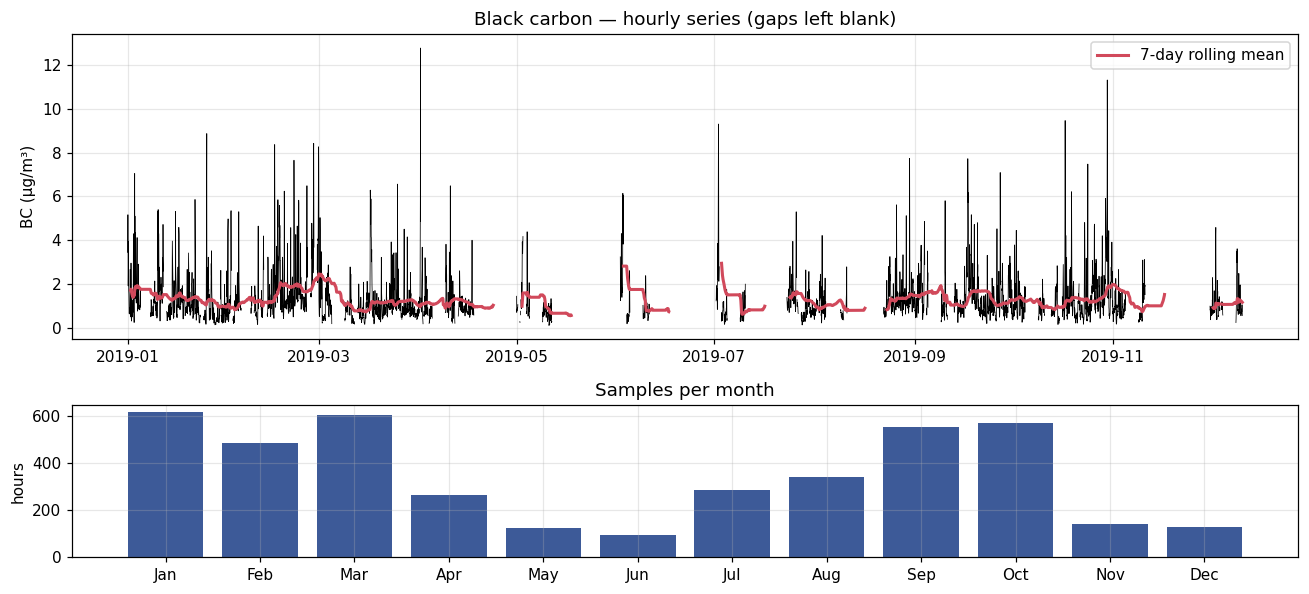

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), gridspec_kw={"height_ratios": [2, 1]})
grid = df.reindex(pd.date_range(df.index.min(), df.index.max(), freq="h"))
axes[0].plot(grid.index, grid["BC"], lw=0.5, color="k")
axes[0].plot(grid["BC"].rolling(24 * 7, min_periods=24).mean(), color="#d1495b", lw=2, label="7-day rolling mean")
axes[0].set(ylabel="BC (µg/m³)", title="Black carbon — hourly series (gaps left blank)")
axes[0].legend()
cnt = df.groupby(df.index.month).size()
axes[1].bar(cnt.index, cnt.values, color="#3d5a98")
axes[1].set(xticks=range(1, 13), xticklabels=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"],
            ylabel="hours", title="Samples per month")
fig.tight_layout(); fig.savefig(FIG / "2_timeseries_coverage.pdf", bbox_inches="tight"); plt.show()

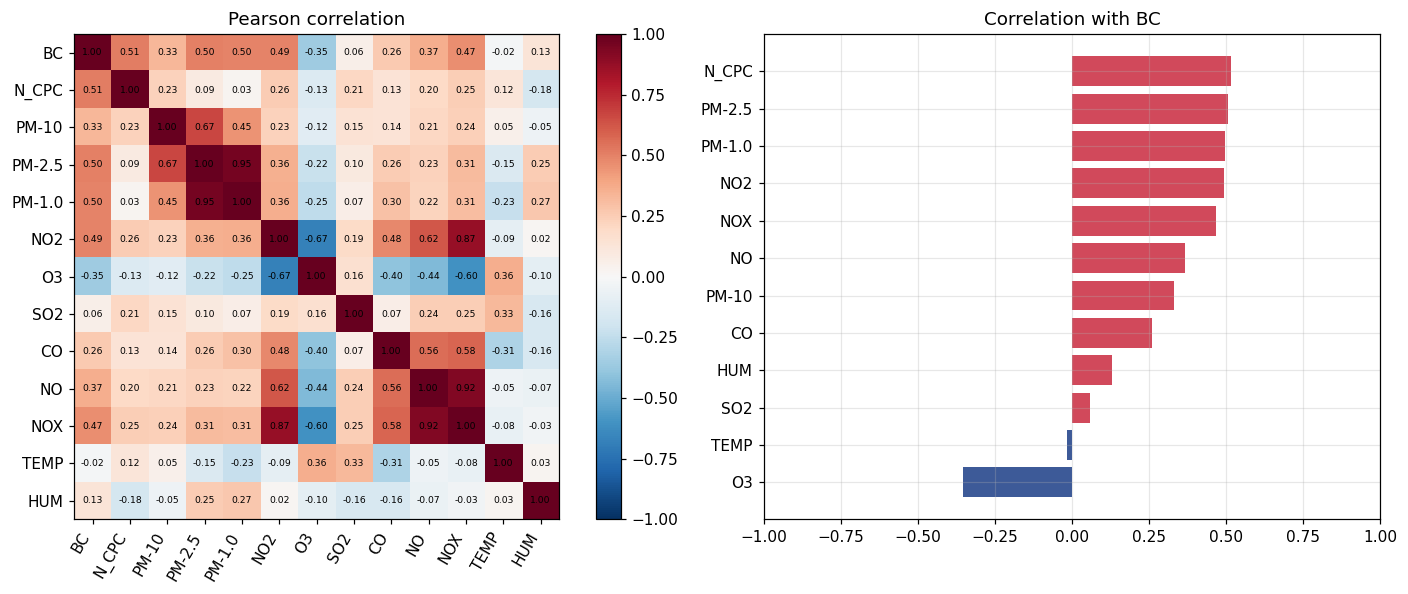

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
C = df.corr()
im = axes[0].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(C)), C.columns, rotation=60, ha="right"); axes[0].set_yticks(range(len(C)), C.columns)
for i in range(len(C)):
    for j in range(len(C)):
        axes[0].text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
axes[0].grid(False); plt.colorbar(im, ax=axes[0], fraction=0.046); axes[0].set_title("Pearson correlation")
r = C["BC"].drop("BC").sort_values()
axes[1].barh(r.index, r.values, color=np.where(r.values > 0, "#d1495b", "#3d5a98"))
axes[1].set(title="Correlation with BC", xlim=(-1, 1))
fig.tight_layout(); fig.savefig(FIG / "2_correlation.pdf", bbox_inches="tight"); plt.show()

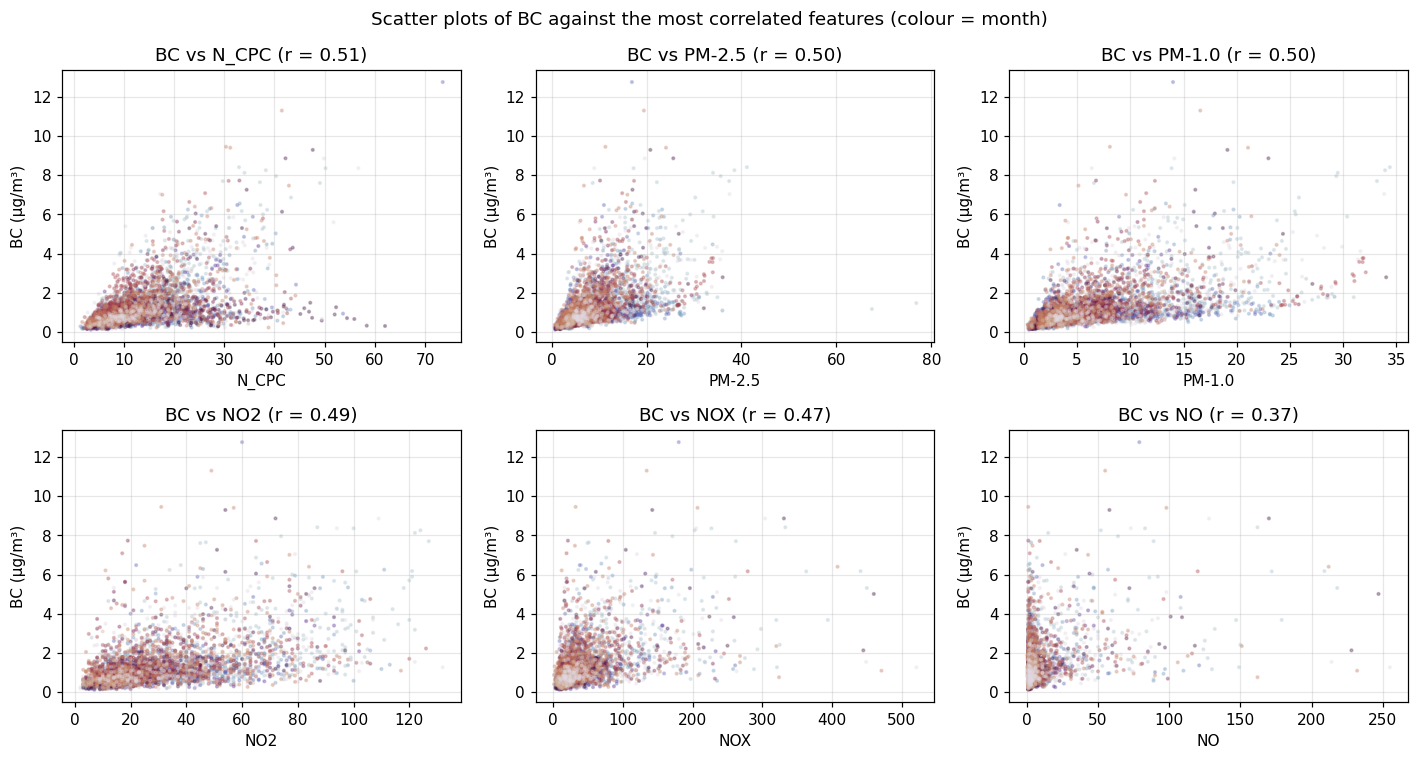

In [5]:
top = C["BC"].drop("BC").abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.ravel(), top):
    ax.scatter(df[f], df["BC"], s=3, alpha=0.3, c=df.index.month, cmap="twilight")
    ax.set(xlabel=f, ylabel="BC (µg/m³)", title=f"BC vs {f} (r = {C.loc['BC', f]:.2f})")
fig.suptitle("Scatter plots of BC against the most correlated features (colour = month)")
fig.tight_layout(); fig.savefig(FIG / "2_scatter.pdf", bbox_inches="tight"); plt.show()

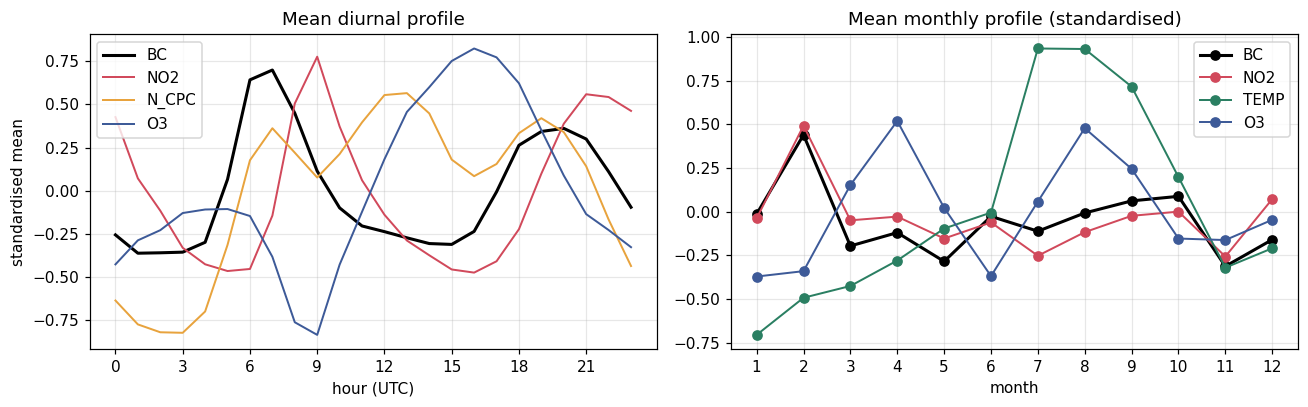

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
z = (df - df.mean()) / df.std()
for f, c in [("BC", "k"), ("NO2", "#d1495b"), ("N_CPC", "#e8a33d"), ("O3", "#3d5a98")]:
    axes[0].plot(z.groupby(z.index.hour)[f].mean(), lw=2 if f == "BC" else 1.3, color=c, label=f)
axes[0].set(xlabel="hour (UTC)", ylabel="standardised mean", title="Mean diurnal profile", xticks=range(0, 24, 3))
axes[0].legend()
for f, c in [("BC", "k"), ("NO2", "#d1495b"), ("TEMP", "#2a7f62"), ("O3", "#3d5a98")]:
    axes[1].plot(z.groupby(z.index.month)[f].mean(), "o-", lw=2 if f == "BC" else 1.3, color=c, label=f)
axes[1].set(xlabel="month", title="Mean monthly profile (standardised)", xticks=range(1, 13))
axes[1].legend()
fig.tight_layout(); fig.savefig(FIG / "2_profiles.pdf", bbox_inches="tight"); plt.show()

### Train/test splits

In [7]:
X, y = df[FEATS], df["BC"]
split = {}
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=SEED, shuffle=True)
split["shuffled"] = (Xa.sort_index(), Xb.sort_index(), ya.sort_index(), yb.sort_index(), KFold(5, shuffle=True, random_state=SEED))
n_tr = int(0.8 * len(df))
split["temporal"] = (X.iloc[:n_tr], X.iloc[n_tr:], y.iloc[:n_tr], y.iloc[n_tr:], TimeSeriesSplit(5))
for k, (Xa, Xb, ya, yb, _) in split.items():
    print(f"{k:9s} train {len(Xa)} ({Xa.index.min():%d %b}–{Xa.index.max():%d %b}), test {len(Xb)} "
          f"({Xb.index.min():%d %b}–{Xb.index.max():%d %b}); BC mean train {ya.mean():.2f}, test {yb.mean():.2f}")

shuffled  train 3378 (01 Jan–10 Dec), test 845 (01 Jan–10 Dec); BC mean train 1.31, test 1.31
temporal  train 3378 (01 Jan–01 Oct), test 845 (01 Oct–10 Dec); BC mean train 1.31, test 1.29


### Forward subset selection (Random Forest)

Greedy: start from the empty set; at each step add the feature that gives the lowest CV RMSE on the training set.
The final subset is the smallest one whose CV RMSE is within 1 % of the best.

In [8]:
def fss(Xa, ya, cv):
    est = RandomForestRegressor(n_estimators=80, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=SEED)
    sel, path = [], []
    remaining = list(Xa.columns)
    while remaining:
        scores = {f: -cross_val_score(est, Xa[sel + [f]], ya, cv=cv, scoring="neg_root_mean_squared_error").mean()
                  for f in remaining}
        best = min(scores, key=scores.get)
        sel.append(best); remaining.remove(best)
        path.append({"k": len(sel), "added": best, "cv_RMSE": scores[best]})
    path = pd.DataFrame(path)
    kbest = path.loc[path.cv_RMSE <= path.cv_RMSE.min() * 1.01, "k"].min()
    return path, sel[:kbest]

fss_res = {}
for k, (Xa, Xb, ya, yb, cv) in split.items():
    t = time.time()
    fss_res[k] = fss(Xa, ya, cv)
    print(f"{k}: selected {len(fss_res[k][1])} features {fss_res[k][1]}  ({time.time()-t:.0f}s)")

shuffled: selected 7 features ['O3', 'N_CPC', 'PM-1.0', 'TEMP', 'NO', 'PM-10', 'HUM']  (34s)


temporal: selected 7 features ['O3', 'N_CPC', 'PM-1.0', 'TEMP', 'PM-10', 'CO', 'HUM']  (27s)


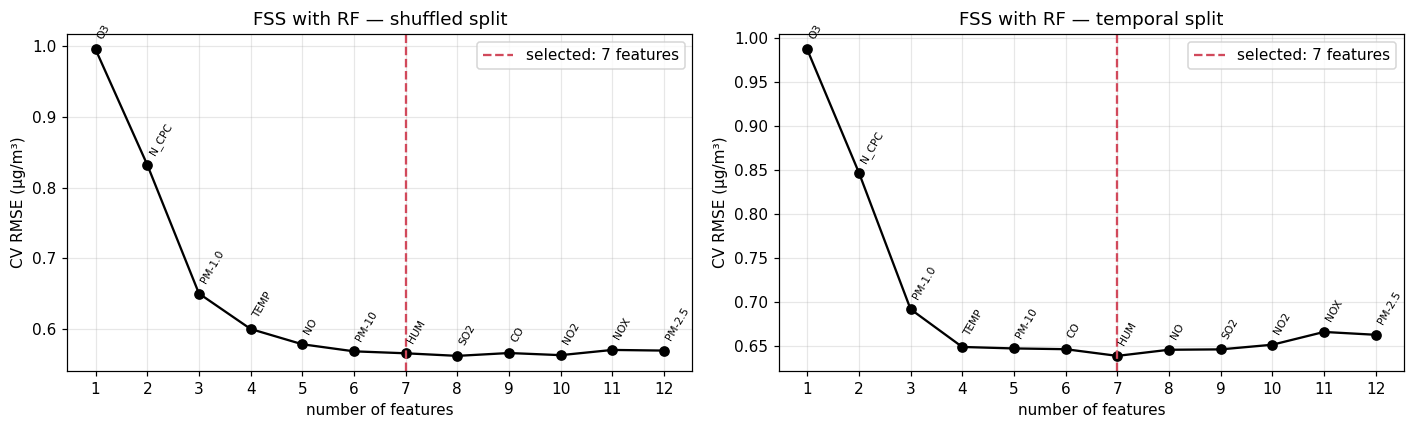

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (k, (path, sel)) in zip(axes, fss_res.items()):
    ax.plot(path.k, path.cv_RMSE, "o-", color="k")
    for _, rrow in path.iterrows():
        ax.annotate(rrow.added, (rrow.k, rrow.cv_RMSE), xytext=(0, 7), textcoords="offset points",
                    rotation=60, fontsize=7, ha="left")
    ax.axvline(len(sel), color="#d1495b", ls="--", label=f"selected: {len(sel)} features")
    ax.set(xlabel="number of features", ylabel="CV RMSE (µg/m³)", title=f"FSS with RF — {k} split", xticks=path.k)
    ax.legend()
fig.tight_layout(); fig.savefig(FIG / "2_fss.pdf", bbox_inches="tight"); plt.show()

### Models and hyperparameter grids

All models are wrapped in a pipeline with `StandardScaler` (needed for SVR, KNN, KRR, FFNN; harmless for trees).

In [10]:
MODELS = {
    "MLR":  (LinearRegression(), {}),
    "SVR":  (SVR(kernel="rbf"), {"m__C": [1, 10, 100], "m__gamma": [0.03, 0.1, 0.3], "m__epsilon": [0.05, 0.2]}),
    "RF":   (RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED),
             {"m__max_depth": [5, 10, 20, None], "m__min_samples_leaf": [1, 3, 10], "m__max_features": [0.33, 0.66, 1.0]}),
    "GBoost": (GradientBoostingRegressor(subsample=0.8, random_state=SEED),
               {"m__n_estimators": [100, 300, 800], "m__learning_rate": [0.03, 0.1], "m__max_depth": [2, 3, 5]}),
    "FFNN": (MLPRegressor(max_iter=3000, early_stopping=True, n_iter_no_change=30, random_state=SEED),
             {"m__hidden_layer_sizes": [(16,), (64,), (64, 32), (128, 64)], "m__alpha": [1e-4, 1e-2, 1, 10]}),
    "KNN":  (KNeighborsRegressor(), {"m__n_neighbors": [3, 5, 10, 20, 40], "m__weights": ["uniform", "distance"]}),
    "KRR":  (KernelRidge(kernel="rbf"), {"m__alpha": [0.01, 0.1, 1], "m__gamma": [0.03, 0.1, 0.3]}),
}

def pipe(est):
    from sklearn.pipeline import Pipeline
    return Pipeline([("s", StandardScaler()), ("m", est)])

results, fitted, cvres = [], {}, {}
for k, (Xa, Xb, ya, yb, cv) in split.items():
    sel = fss_res[k][1]
    for name, (est, grid) in MODELS.items():
        t = time.time()
        gs = GridSearchCV(pipe(est), grid or {"m__fit_intercept": [True]}, cv=cv,
                          scoring="neg_root_mean_squared_error", n_jobs=-1).fit(Xa[sel], ya)
        yhat = gs.predict(Xb[sel])
        fitted[(k, name)] = yhat; cvres[(k, name)] = pd.DataFrame(gs.cv_results_)
        results.append(dict(split=k, model=name, R2=r2_score(yb, yhat), MAE=mean_absolute_error(yb, yhat),
                            RMSE=np.sqrt(mean_squared_error(yb, yhat)), cv_RMSE=-gs.best_score_,
                            best_params={p.replace("m__", ""): v for p, v in gs.best_params_.items()},
                            secs=round(time.time() - t, 1)))
        print(f"{k:9s} {name:7s} R2={results[-1]['R2']:.3f}  RMSE={results[-1]['RMSE']:.3f}  ({results[-1]['secs']}s) {results[-1]['best_params']}")
res = pd.DataFrame(results)
res.to_csv("results_2_models.csv", index=False)

shuffled  MLR     R2=0.513  RMSE=0.808  (3.0s) {'fit_intercept': True}


shuffled  SVR     R2=0.736  RMSE=0.594  (16.3s) {'C': 100, 'epsilon': 0.2, 'gamma': 0.03}


shuffled  RF      R2=0.735  RMSE=0.596  (50.9s) {'max_depth': None, 'max_features': 0.66, 'min_samples_leaf': 1}


shuffled  GBoost  R2=0.781  RMSE=0.541  (37.5s) {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 800}


shuffled  FFNN    R2=0.782  RMSE=0.540  (20.2s) {'alpha': 0.01, 'hidden_layer_sizes': (128, 64)}


...

temporal  RF      R2=0.640  RMSE=0.671  (32.5s) {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 3}


temporal  GBoost  R2=0.637  RMSE=0.674  (18.2s) {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300}


temporal  FFNN    R2=0.669  RMSE=0.644  (11.4s) {'alpha': 0.01, 'hidden_layer_sizes': (64,)}


temporal  KNN     R2=0.596  RMSE=0.711  (0.2s) {'n_neighbors': 10, 'weights': 'distance'}


temporal  KRR     R2=0.668  RMSE=0.645  (2.7s) {'alpha': 0.1, 'gamma': 0.03}


### Test-set comparison

In [11]:
tab = res.pivot(index="model", columns="split", values=["R2", "MAE", "RMSE"]).round(3)
tab = tab.loc[list(MODELS)]
tab

R2               MAE              RMSE         
split  shuffled temporal shuffled temporal shuffled temporal
model                                                       
MLR       0.513    0.521    0.503    0.460    0.808    0.774
SVR       0.736    0.638    0.351    0.374    0.594    0.673
RF        0.735    0.640    0.353    0.395    0.596    0.671
GBoost    0.781    0.637    0.331    0.399    0.541    0.674
FFNN      0.782    0.669    0.333    0.407    0.540    0.644
KNN       0.704    0.596    0.362    0.422    0.630    0.711
KRR       0.740    0.668    0.358    0.371    0.590    0.645

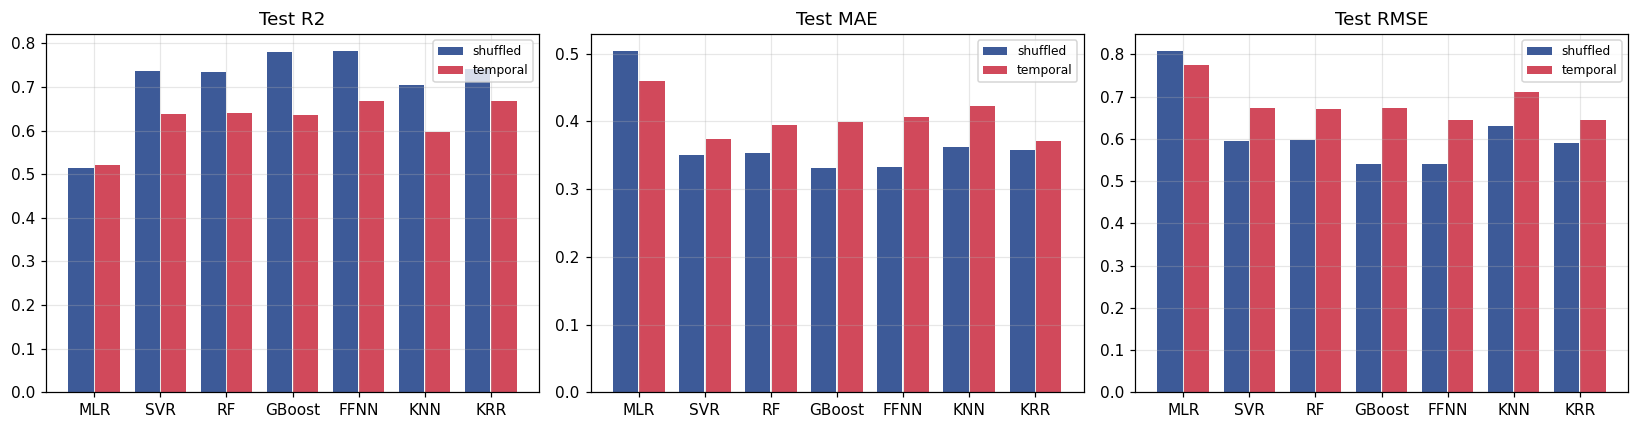

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
names = list(MODELS); x = np.arange(len(names))
for ax, metric in zip(axes, ["R2", "MAE", "RMSE"]):
    for off, k, c in [(-0.2, "shuffled", "#3d5a98"), (0.2, "temporal", "#d1495b")]:
        v = res[res.split == k].set_index("model").loc[names, metric]
        ax.bar(x + off, v, width=0.38, color=c, label=k)
    ax.set_xticks(x, names); ax.set_title(f"Test {metric}")
    ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "2_model_comparison.pdf", bbox_inches="tight"); plt.show()

### Hyperparameter sensitivity (CV RMSE for both splits; each point is the best over the other parameters)

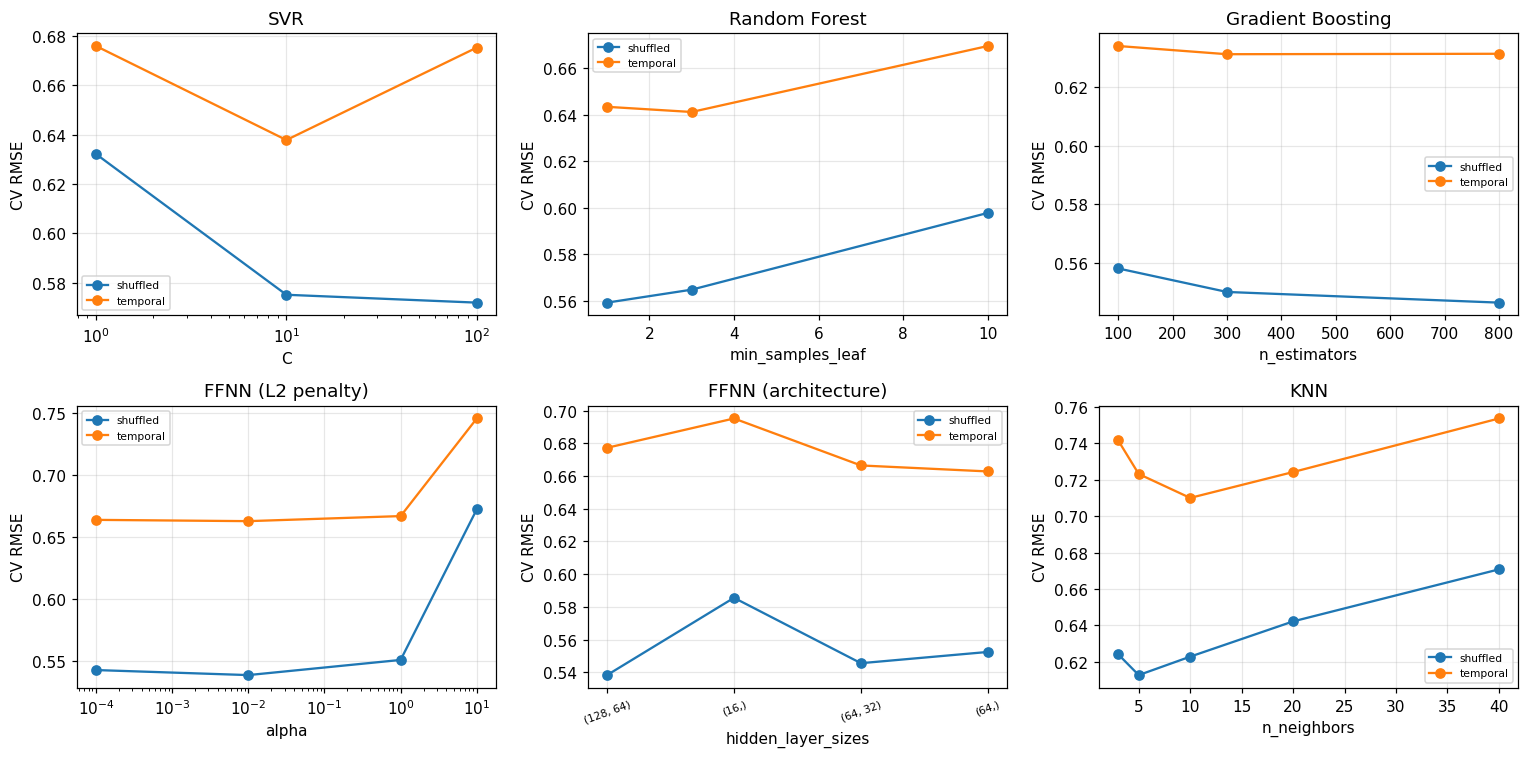

In [13]:
def hp_curve(ax, key, param, logx=False, label=None):
    d = cvres[key].copy()
    d["rmse"] = -d["mean_test_score"]
    col = f"param_m__{param}"
    g = d.groupby(d[col].astype(str))["rmse"].min()
    try:
        g.index = g.index.astype(float); g = g.sort_index()
        (ax.semilogx if logx else ax.plot)(g.index, g.values, "o-", label=label)
    except ValueError:
        ax.plot(range(len(g)), g.values, "o-", label=label); ax.set_xticks(range(len(g)), g.index, rotation=20, fontsize=7)
    ax.set(xlabel=param, ylabel="CV RMSE")

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for k, ls in [("shuffled", None), ("temporal", None)]:
    hp_curve(axes[0, 0], (k, "SVR"), "C", logx=True, label=k);           axes[0, 0].set_title("SVR")
    hp_curve(axes[0, 1], (k, "RF"), "min_samples_leaf", label=k);       axes[0, 1].set_title("Random Forest")
    hp_curve(axes[0, 2], (k, "GBoost"), "n_estimators", label=k);       axes[0, 2].set_title("Gradient Boosting")
    hp_curve(axes[1, 0], (k, "FFNN"), "alpha", logx=True, label=k);     axes[1, 0].set_title("FFNN (L2 penalty)")
    hp_curve(axes[1, 1], (k, "FFNN"), "hidden_layer_sizes", label=k);   axes[1, 1].set_title("FFNN (architecture)")
    hp_curve(axes[1, 2], (k, "KNN"), "n_neighbors", label=k);           axes[1, 2].set_title("KNN")
for ax in axes.ravel(): ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "2_hyperparams.pdf", bbox_inches="tight"); plt.show()

### Predictions in time (temporality recovered for both scenarios)

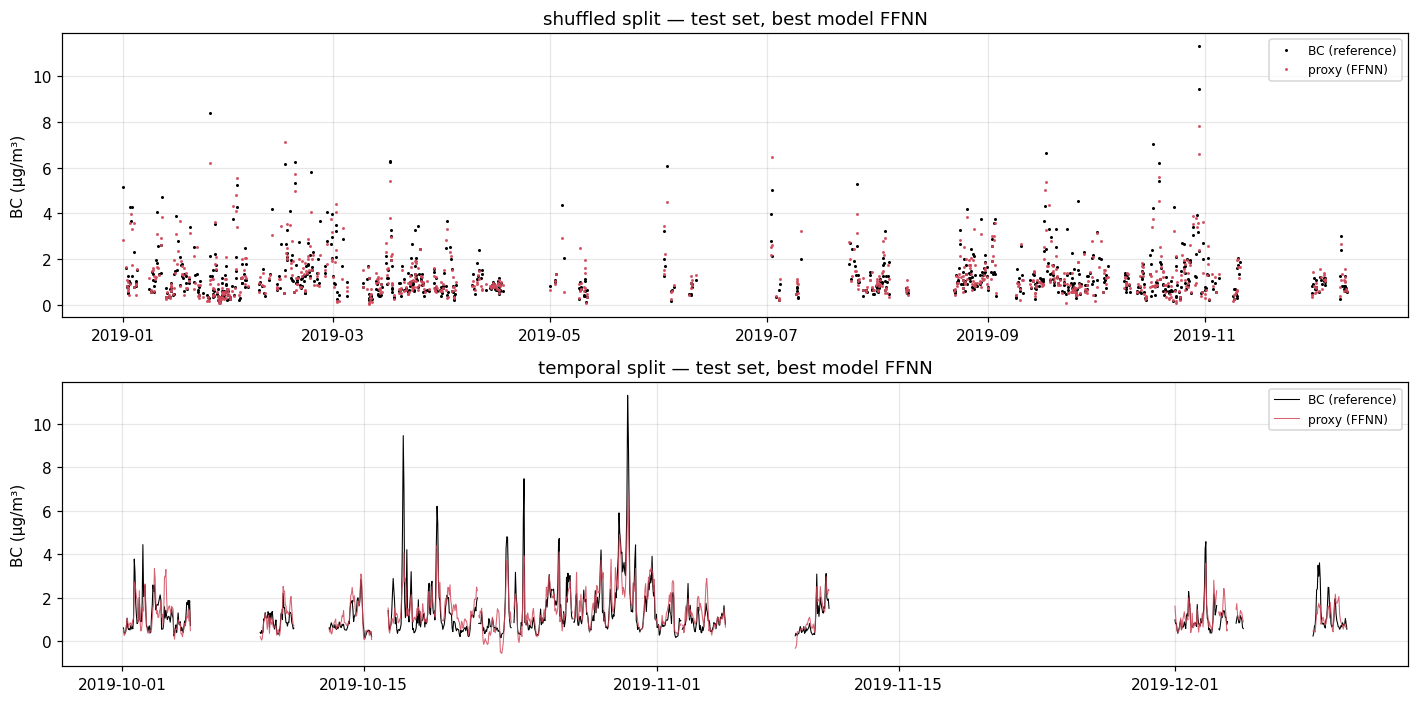

In [14]:
best = {k: res[res.split == k].sort_values("RMSE").iloc[0].model for k in split}
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5))
for ax, k in zip(axes, split):
    yb = split[k][3]
    g = pd.DataFrame({"true": yb, "pred": fitted[(k, best[k])]}, index=yb.index)
    g = g.reindex(pd.date_range(g.index.min(), g.index.max(), freq="h")) if k == "temporal" else g
    ax.plot(g.index, g["true"], color="k", lw=0.7, label="BC (reference)")
    ax.plot(g.index, g["pred"], color="#d1495b", lw=0.7, alpha=0.85, label=f"proxy ({best[k]})")
    ax.set(ylabel="BC (µg/m³)", title=f"{k} split — test set, best model {best[k]}")
    if k == "shuffled": ax.lines[0].set_linestyle("none"); ax.lines[0].set_marker("."); ax.lines[0].set_markersize(2)
    if k == "shuffled": ax.lines[1].set_linestyle("none"); ax.lines[1].set_marker("."); ax.lines[1].set_markersize(2)
    ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "2_predictions_time.pdf", bbox_inches="tight"); plt.show()

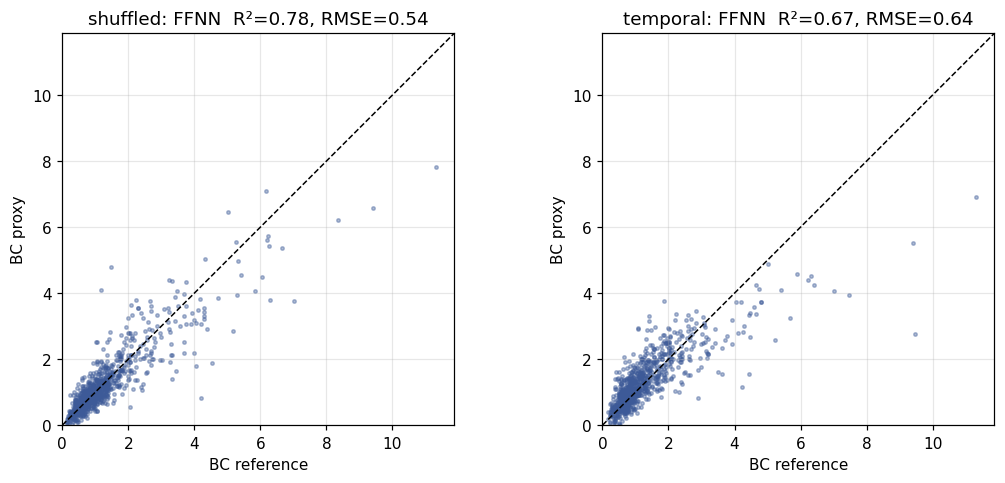

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, k in zip(axes, split):
    yb = split[k][3]; yh = fitted[(k, best[k])]
    lim = [0, max(yb.max(), yh.max()) * 1.05]
    ax.scatter(yb, yh, s=5, alpha=0.4, color="#3d5a98")
    ax.plot(lim, lim, "k--", lw=1)
    r = res[(res.split == k) & (res.model == best[k])].iloc[0]
    ax.set(xlim=lim, ylim=lim, xlabel="BC reference", ylabel="BC proxy",
           title=f"{k}: {best[k]}  R²={r.R2:.2f}, RMSE={r.RMSE:.2f}")
    ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(FIG / "2_scatter_best.pdf", bbox_inches="tight"); plt.show()

### Feature importance (RF, shuffled split)

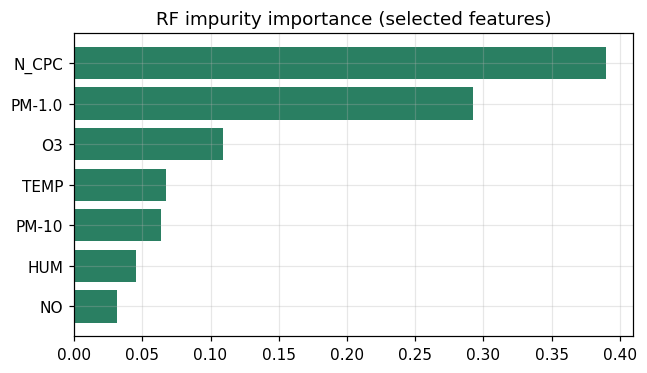

In [16]:
sel = fss_res["shuffled"][1]
rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED).fit(split["shuffled"][0][sel], split["shuffled"][2])
imp = pd.Series(rf.feature_importances_, index=sel).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(imp.index, imp.values, color="#2a7f62"); ax.set(title="RF impurity importance (selected features)")
fig.tight_layout(); fig.savefig(FIG / "2_importance.pdf", bbox_inches="tight"); plt.show()

### Observations (draft, to refine)

- BC correlates most with traffic tracers (NO$_2$, NO$_x$, N_CPC, PM$_{2.5}$/PM$_1$) and negatively with O$_3$ (titration by NO).
- Coverage is very uneven: dense in winter/spring and autumn, sparse in May–June. The temporal split trains mostly on
  winter–summer and tests on the autumn: a different regime → concept drift.
- Shuffled split gives clearly better metrics than the temporal split for every model; the gap measures how much of the
  "performance" comes from having seen similar conditions in training.
- Non-linear models beat MLR; ensemble trees / SVR are typically the strongest.